# Question 6 – Regression Analysis
## Scenario: Residential Property Price Prediction (20 houses)

| Task | Description | Marks |
|---|---|---|
| a | Prepare data; exploratory analysis of area and price | 10 |
| b | Scatter plot; is a linear relationship appropriate? | 10 |
| c | Fit simple linear regression; derive the equation | 15 |
| d | Interpret slope, intercept and R² | 15 |
| e | MAE, MSE, RMSE and predictive performance | 15 |
| f | Fitted line and residual plots; assumption checks | 15 |
| g | Predict the price of a 1,850 sq. ft. property | 10 |
| h | Limitations and improvements | 10 |

> **How to use:** run all cells in order (Jupyter or Colab). The model is fitted **three ways**: by hand with the least-squares formulas, with `scikit-learn`, and with `scipy`. All three give the same answer, so you can use whichever your examiner expects.
> **Exam tip:** change only the data lists if the numbers differ.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", "{:.4f}".format)

## (a) Prepare the dataset and exploratory analysis  *(10 marks)*

In [2]:
df = pd.DataFrame({
    "House": [f"H{i}" for i in range(1, 21)],
    "Area":  [800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700,
              1800, 1900, 2000, 2100, 2200, 2300, 2400, 2500, 2600, 2700],     # sq. ft.
    "Price": [32, 35, 39, 42, 47, 50, 54, 58, 62, 65,
              70, 73, 78, 81, 85, 88, 93, 96, 101, 105],                        # ₹ lakh
})
print("Shape:", df.shape, "| Missing:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
print("Data types:\n", df.dtypes, sep="")
print("All areas and prices positive?", (df[["Area", "Price"]] > 0).all().all())
df

Shape: (20, 3) | Missing: 0 | Duplicates: 0
Data types:
House      str
Area     int64
Price    int64
dtype: object
All areas and prices positive? True


,House,Area,Price
0,H1,800,32
1,H2,900,35
2,H3,1000,39
3,H4,1100,42
4,H5,1200,47
5,H6,1300,50
6,H7,1400,54
7,H8,1500,58
8,H9,1600,62
9,H10,1700,65


In [3]:
eda = df[["Area", "Price"]].describe().T
eda["median"] = df[["Area", "Price"]].median()
eda["IQR"] = eda["75%"] - eda["25%"]
eda["CV_%"] = eda["std"] / eda["mean"] * 100
eda["skewness"] = df[["Area", "Price"]].skew()
display(eda)

df["Price_per_sqft_Rs"] = df["Price"] * 1e5 / df["Area"]        # 1 lakh = ₹1,00,000
print(f"Price per sq. ft. ranges from ₹{df['Price_per_sqft_Rs'].min():,.0f} to ₹{df['Price_per_sqft_Rs'].max():,.0f} "
      f"(mean ₹{df['Price_per_sqft_Rs'].mean():,.0f})")
print("Consecutive price increases for each +100 sq. ft.:", df["Price"].diff().dropna().astype(int).tolist())

,count,mean,std,min,25%,50%,75%,max,median,IQR,CV_%,skewness
Area,20.0000,1750.0000,591.6080,800.0000,1275.0000,1750.0000,2225.0000,2700.0000,1750.0000,950.0000,33.8062,0.0000
Price,20.0000,67.7000,22.7806,32.0000,49.2500,67.5000,85.7500,105.0000,67.5000,36.5000,33.6494,0.0279


Price per sq. ft. ranges from ₹3,818 to ₹4,000 (mean ₹3,873)
Consecutive price increases for each +100 sq. ft.: [3, 4, 3, 5, 3, 4, 4, 4, 3, 5, 3, 5, 3, 4, 3, 5, 3, 5, 4]


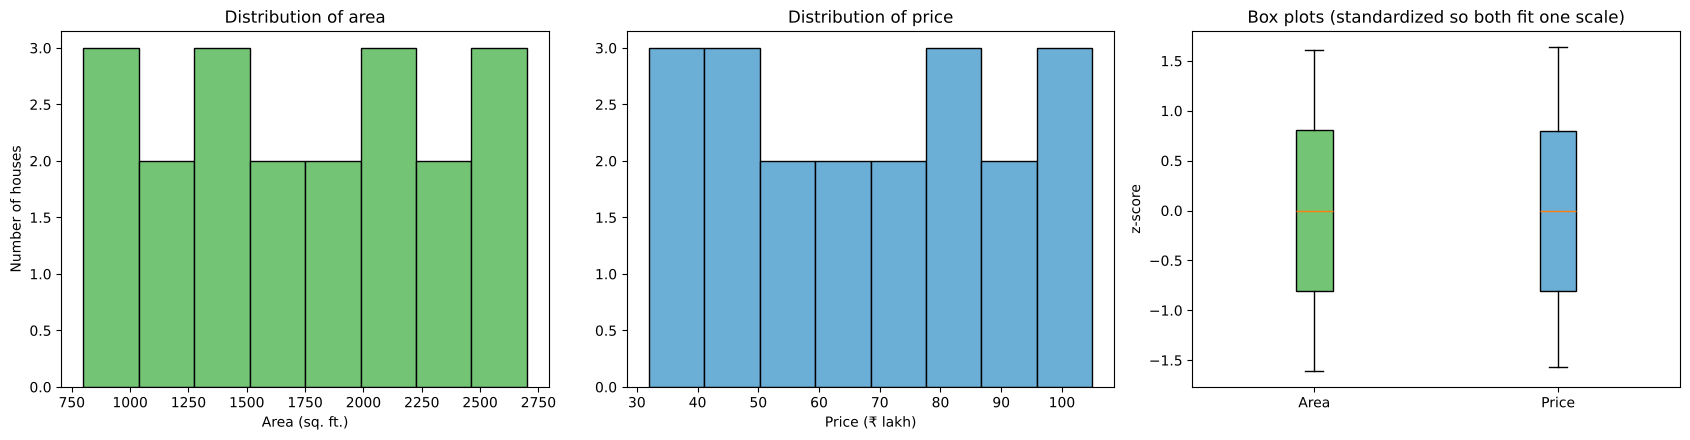

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(df["Area"], bins=8, color="#74c476", edgecolor="black")
axes[0].set_title("Distribution of area")
axes[0].set_xlabel("Area (sq. ft.)")
axes[0].set_ylabel("Number of houses")
axes[1].hist(df["Price"], bins=8, color="#6baed6", edgecolor="black")
axes[1].set_title("Distribution of price")
axes[1].set_xlabel("Price (₹ lakh)")
bp = axes[2].boxplot([(df["Area"] - df["Area"].mean()) / df["Area"].std(),
                      (df["Price"] - df["Price"].mean()) / df["Price"].std()], patch_artist=True)
for p, c in zip(bp["boxes"], ["#74c476", "#6baed6"]):
    p.set_facecolor(c)
axes[2].set_xticks([1, 2])
axes[2].set_xticklabels(["Area", "Price"])
axes[2].set_ylabel("z-score")
axes[2].set_title("Box plots (standardized so both fit one scale)")
plt.tight_layout()
plt.show()

**EDA findings:**
* **Area** is spread **evenly** from 800 to 2,700 sq. ft. in steps of 100 (mean = median = 1,750, SD ≈ 592). The data looks like a designed sample rather than a random one.
* **Price** ranges from ₹32 to ₹105 lakh (mean ₹67.70 lakh, median ₹67.50 lakh, SD ≈ ₹22.78 lakh).
* Both variables are **symmetric** (skewness ≈ 0) and have similar relative spread (CV ≈ 34%). There are **no missing values, duplicates or outliers**.
* **Price per sq. ft. is almost constant**, between ₹3,818 and ₹4,000 (mean ₹3,873). Every extra 100 sq. ft. adds ₹3–5 lakh. Both facts already suggest a **straight-line, nearly proportional** relationship.

## (b) Scatter plot – is a linear model appropriate?  *(10 marks)*

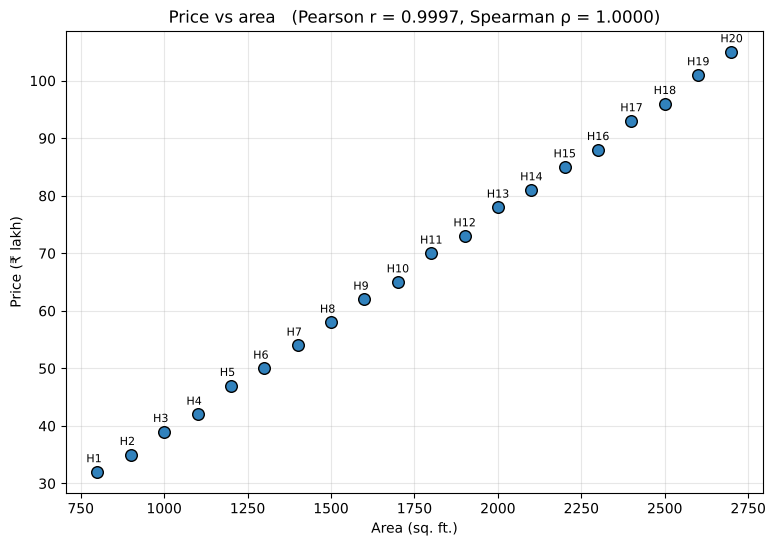

Pearson correlation r = 0.999738


In [5]:
r = df["Area"].corr(df["Price"])
r_s = stats.spearmanr(df["Area"], df["Price"])[0]

plt.figure(figsize=(9, 6))
plt.scatter(df["Area"], df["Price"], s=70, color="#3182bd", edgecolor="black", zorder=3)
for _, row in df.iterrows():
    plt.annotate(row["House"], (row["Area"], row["Price"]), xytext=(-8, 7), textcoords="offset points", fontsize=8)
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price (₹ lakh)")
plt.title(f"Price vs area   (Pearson r = {r:.4f}, Spearman ρ = {r_s:.4f})")
plt.grid(alpha=0.3)
plt.show()

print(f"Pearson correlation r = {r:.6f}")

**Assessment:** the points form an almost perfect **straight, upward-sloping line**. There is no visible curve, no fan shape and no outlier, and the Pearson correlation is **r = 0.9997** (Spearman ρ = 1, a perfectly monotonic relationship). A **simple linear regression is appropriate**. (Part f checks this more carefully with the residuals.)

## (c) Fit the simple linear regression and derive the equation  *(15 marks)*

Model: $\text{Price} = \beta_0 + \beta_1 \times \text{Area} + \varepsilon$

Least-squares estimates:

$$\beta_1 = \frac{S_{xy}}{S_{xx}} = \frac{\sum (x-\bar{x})(y-\bar{y})}{\sum (x-\bar{x})^2}, \qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

### Method 1 – by hand (formulas)

In [6]:
x = df["Area"].values.astype(float)
y = df["Price"].values.astype(float)
n = len(x)

x_bar, y_bar = x.mean(), y.mean()
Sxx = np.sum((x - x_bar) ** 2)
Sxy = np.sum((x - x_bar) * (y - y_bar))
b1 = Sxy / Sxx
b0 = y_bar - b1 * x_bar

print(f"x̄ = {x_bar}, ȳ = {y_bar}")
print(f"Sxx = {Sxx:,.1f},  Sxy = {Sxy:,.1f}")
print(f"Slope     β1 = Sxy / Sxx = {Sxy:,.1f} / {Sxx:,.1f} = {b1:.6f}")
print(f"Intercept β0 = ȳ - β1·x̄ = {y_bar} - {b1:.6f} × {x_bar} = {b0:.6f}")

x̄ = 1750.0, ȳ = 67.7
Sxx = 6,650,000.0,  Sxy = 256,000.0
Slope     β1 = Sxy / Sxx = 256,000.0 / 6,650,000.0 = 0.038496
Intercept β0 = ȳ - β1·x̄ = 67.7 - 0.038496 × 1750.0 = 0.331579


### Method 2 – scikit-learn

In [7]:
X = df[["Area"]]                 # sklearn needs a 2-D input (a DataFrame / column), not a 1-D list
model = LinearRegression()
model.fit(X, df["Price"])
print(f"sklearn: slope = {model.coef_[0]:.6f}, intercept = {model.intercept_:.6f}")

sklearn: slope = 0.038496, intercept = 0.331579


### Method 3 – SciPy (also gives standard errors and a p-value)

In [8]:
lr = stats.linregress(x, y)
print(f"scipy  : slope = {lr.slope:.6f}, intercept = {lr.intercept:.6f}, r = {lr.rvalue:.6f}")
print(f"         SE(slope) = {lr.stderr:.6f}, SE(intercept) = {lr.intercept_stderr:.6f}, p-value (slope) = {lr.pvalue:.3e}")

t_slope = lr.slope / lr.stderr
t_crit = stats.t.ppf(0.975, n - 2)
ci_slope = (lr.slope - t_crit * lr.stderr, lr.slope + t_crit * lr.stderr)
print(f"\nt-test for slope: t = {t_slope:.2f}, df = {n - 2}, critical t = {t_crit:.3f} -> slope is significant")
t_int = lr.intercept / lr.intercept_stderr
p_int = 2 * stats.t.sf(abs(t_int), n - 2)
print(f"t-test for intercept: t = {t_int:.3f}, p = {p_int:.4f} -> "
      f"{'NOT significantly different from 0' if p_int > 0.05 else 'significantly different from 0'}")
print(f"95% CI for slope: ({ci_slope[0]:.6f}, {ci_slope[1]:.6f}) ₹ lakh per sq. ft.")

assert np.isclose(b1, model.coef_[0]) and np.isclose(b1, lr.slope)
print("\nAll three methods agree ✔")
print(f"\nREGRESSION EQUATION:  Price (₹ lakh) = {b0:.4f} + {b1:.4f} × Area (sq. ft.)")

scipy  : slope = 0.038496, intercept = 0.331579, r = 0.999738
         SE(slope) = 0.000208, SE(intercept) = 0.382648, p-value (slope) = 5.484e-31

t-test for slope: t = 185.37, df = 18, critical t = 2.101 -> slope is significant
t-test for intercept: t = 0.867, p = 0.3976 -> NOT significantly different from 0
95% CI for slope: (0.038060, 0.038933) ₹ lakh per sq. ft.

All three methods agree ✔

REGRESSION EQUATION:  Price (₹ lakh) = 0.3316 + 0.0385 × Area (sq. ft.)


## (d) Interpreting the slope, intercept and R²  *(15 marks)*

$$R^2 = 1 - \frac{SSE}{SST} = \frac{SSR}{SST}, \quad SST = \sum (y-\bar{y})^2,\; SSE = \sum (y-\hat{y})^2,\; SSR = \sum (\hat{y}-\bar{y})^2$$

In [9]:
y_hat = b0 + b1 * x
SST = np.sum((y - y_bar) ** 2)
SSE = np.sum((y - y_hat) ** 2)
SSR = np.sum((y_hat - y_bar) ** 2)
R2 = 1 - SSE / SST
adj_R2 = 1 - (1 - R2) * (n - 1) / (n - 2)

print(f"SST = {SST:.4f}   SSR = {SSR:.4f}   SSE = {SSE:.4f}   (SSR + SSE = {SSR + SSE:.4f})")
print(f"R² = 1 - SSE/SST = 1 - {SSE:.4f}/{SST:.4f} = {R2:.6f}")
print(f"Check: r² = {r ** 2:.6f},  sklearn R² = {model.score(X, df['Price']):.6f}")
print(f"Adjusted R² = {adj_R2:.6f}")

print(f"\nSlope per 100 sq. ft. = {b1 * 100:.4f} lakh = ₹{b1 * 100 * 1e5:,.0f}")
print(f"Slope per sq. ft.     = {b1:.6f} lakh = ₹{b1 * 1e5:,.2f}")

SST = 9860.2000   SSR = 9855.0376   SSE = 5.1624   (SSR + SSE = 9860.2000)
R² = 1 - SSE/SST = 1 - 5.1624/9860.2000 = 0.999476
Check: r² = 0.999476,  sklearn R² = 0.999476
Adjusted R² = 0.999447

Slope per 100 sq. ft. = 3.8496 lakh = ₹384,962
Slope per sq. ft.     = 0.038496 lakh = ₹3,849.62


**Interpretation**

* **Slope β₁ = 0.0385 lakh per sq. ft. (0.038496).** Each additional square foot is associated with an average price increase of about **₹3,850**. Equivalently, every **extra 100 sq. ft. adds about ₹3.85 lakh**. The slope is highly significant (t ≈ 185, p ≈ 5 × 10⁻³¹), and its 95% CI (0.03806 to 0.03893) is very narrow.
* **Intercept β₀ = 0.33 lakh (≈ ₹33,000).** Mathematically, this is the predicted price of a house with **0 sq. ft.** That has **no practical meaning**: no house has zero area, and 0 is far outside the observed range (800–2,700 sq. ft.), so interpreting it would be **extrapolation**. The intercept only positions the line. It is also **not statistically different from 0** (p ≈ 0.40), which means price is essentially **proportional** to area (about ₹3,850 per sq. ft.).
* **R² = 0.9995.** About **99.95% of the variation in house prices is explained by area** alone. Only 0.05% is left to other factors, rounding of prices or random noise. Adjusted R² (0.9994) is almost the same, as expected with a single predictor. This is an exceptionally good fit.

## (e) MAE, MSE and RMSE  *(15 marks)*

| Metric | Formula | Meaning |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y-\hat{y}\rvert$ | average absolute error (₹ lakh) |
| **MSE** | $\frac{1}{n}\sum (y-\hat{y})^2$ | average squared error (₹ lakh²); penalizes large errors |
| **RMSE** | $\sqrt{MSE}$ | typical error, back in ₹ lakh |
| **MAPE** | $\frac{100}{n}\sum \left\lvert\frac{y-\hat{y}}{y}\right\rvert$ | average % error (extra) |

In [10]:
resid = y - y_hat
MAE = np.mean(np.abs(resid))
MSE = np.mean(resid ** 2)
RMSE = np.sqrt(MSE)
MAPE = np.mean(np.abs(resid / y)) * 100
SE_reg = np.sqrt(SSE / (n - 2))          # residual standard error (uses n-2 degrees of freedom)

print(f"MAE  = {MAE:.4f} lakh  (₹{MAE * 1e5:,.0f})")
print(f"MSE  = {MSE:.4f} lakh²")
print(f"RMSE = {RMSE:.4f} lakh  (₹{RMSE * 1e5:,.0f})")
print(f"MAPE = {MAPE:.3f} %")
print(f"Residual standard error s = sqrt(SSE/(n-2)) = {SE_reg:.4f} lakh")

# Cross-check with sklearn
print("\nsklearn check:", round(mean_absolute_error(y, y_hat), 4), round(mean_squared_error(y, y_hat), 4),
      round(np.sqrt(mean_squared_error(y, y_hat)), 4), round(r2_score(y, y_hat), 6))

MAE  = 0.4248 lakh  (₹42,481)
MSE  = 0.2581 lakh²
RMSE = 0.5081 lakh  (₹50,806)
MAPE = 0.695 %
Residual standard error s = sqrt(SSE/(n-2)) = 0.5355 lakh

sklearn check: 0.4248 0.2581 0.5081 0.999476


In [11]:
table = df[["House", "Area", "Price"]].copy()
table["Predicted"] = y_hat
table["Residual"] = resid
table["Abs % error"] = np.abs(resid / y) * 100
display(table)

,House,Area,Price,Predicted,Residual,Abs % error
0,H1,800,32,31.1286,0.8714,2.7232
1,H2,900,35,34.9782,0.0218,0.0623
2,H3,1000,39,38.8278,0.1722,0.4415
3,H4,1100,42,42.6774,-0.6774,1.6130
4,H5,1200,47,46.5271,0.4729,1.0062
5,H6,1300,50,50.3767,-0.3767,0.7534
6,H7,1400,54,54.2263,-0.2263,0.4191
7,H8,1500,58,58.0759,-0.0759,0.1309
8,H9,1600,62,61.9256,0.0744,0.1201
9,H10,1700,65,65.7752,-0.7752,1.1926


In [12]:
# Honest check on unseen data: leave-one-out cross-validation (fit on 19 houses, predict the 20th)
loo_err = []
for i in range(n):
    mask = np.arange(n) != i
    s, c = np.polyfit(x[mask], y[mask], 1)
    loo_err.append(y[i] - (c + s * x[i]))
loo_err = np.array(loo_err)
print(f"Leave-one-out CV:  MAE = {np.mean(np.abs(loo_err)):.4f} lakh,  RMSE = {np.sqrt(np.mean(loo_err ** 2)):.4f} lakh")

Leave-one-out CV:  MAE = 0.4779 lakh,  RMSE = 0.5765 lakh


**Assessment of predictive performance:**
* **MAE = ₹0.42 lakh (≈ ₹42,500):** predictions are off by this amount on average.
* **MSE = 0.258 lakh²:** this is in squared units and hard to interpret directly. It is used mainly to compare models.
* **RMSE = ₹0.51 lakh (≈ ₹51,000):** the typical error. It is a little larger than MAE because squaring gives more weight to bigger errors (the largest are about ±₹0.87 lakh, at H1 and H16).
* The typical error is under **1% of the average price** (MAPE ≈ 0.7%, RMSE/mean ≈ 0.75%).
* **Leave-one-out cross-validation** gives nearly the same errors (MAE ≈ 0.48, RMSE ≈ 0.58 lakh), so the model is **not overfitting** and should predict new houses within this size range just as well.
* For property valuation, an error of about ₹50,000 on a ₹68 lakh house is **excellent**. The remaining errors are of the same size as rounding prices to whole lakhs.

## (f) Fitted regression line and residual analysis  *(15 marks)*

Linear regression assumes:
1. **Linearity:** residuals show no curved pattern against the fitted values.
2. **Independence:** no systematic pattern in the order of the residuals (Durbin–Watson ≈ 2).
3. **Homoscedasticity:** residual spread is constant (no funnel shape).
4. **Normality of residuals:** Q–Q plot and Shapiro–Wilk test.

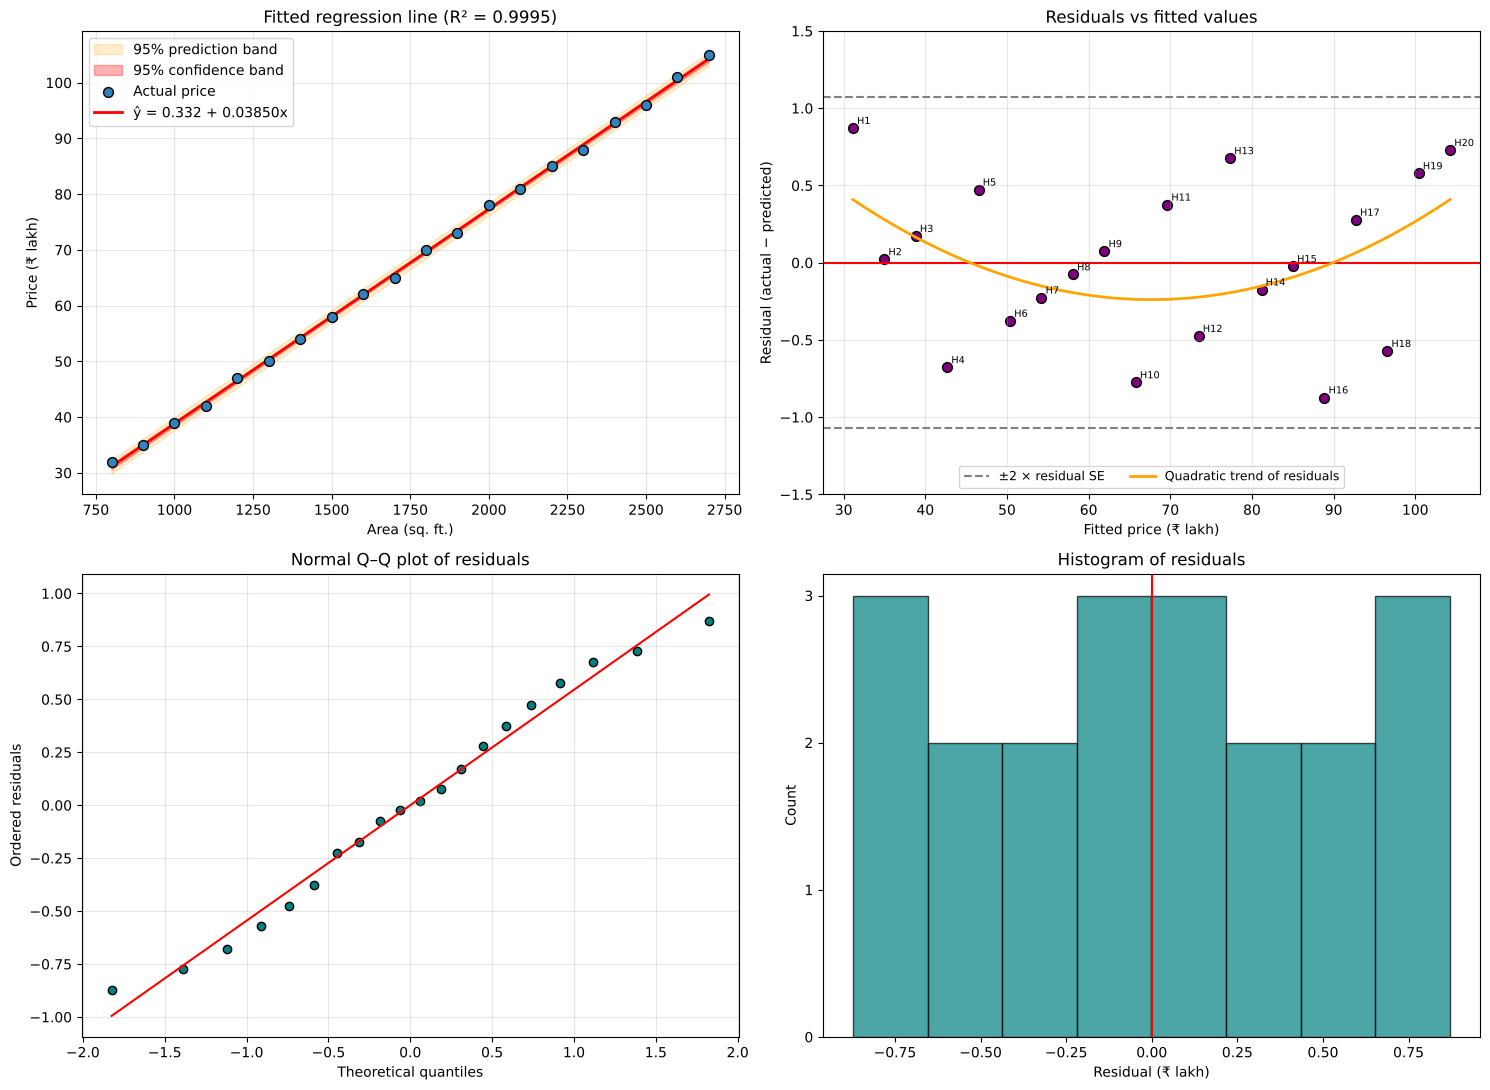

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Fitted line with 95% confidence band and 95% prediction band
ax = axes[0, 0]
xs = np.linspace(x.min(), x.max(), 200)
ys = b0 + b1 * xs
se_mean = SE_reg * np.sqrt(1 / n + (xs - x_bar) ** 2 / Sxx)
se_pred = SE_reg * np.sqrt(1 + 1 / n + (xs - x_bar) ** 2 / Sxx)
ax.fill_between(xs, ys - t_crit * se_pred, ys + t_crit * se_pred, color="orange", alpha=0.2, label="95% prediction band")
ax.fill_between(xs, ys - t_crit * se_mean, ys + t_crit * se_mean, color="red", alpha=0.3, label="95% confidence band")
ax.scatter(x, y, color="#3182bd", edgecolor="black", s=50, zorder=3, label="Actual price")
ax.plot(xs, ys, color="red", lw=2, label=f"ŷ = {b0:.3f} + {b1:.5f}x")
ax.set_xlabel("Area (sq. ft.)")
ax.set_ylabel("Price (₹ lakh)")
ax.set_title(f"Fitted regression line (R² = {R2:.4f})")
ax.legend()
ax.grid(alpha=0.3)

# 2. Residuals vs fitted values
ax = axes[0, 1]
ax.scatter(y_hat, resid, color="purple", edgecolor="black", s=50)
ax.axhline(0, color="red", lw=1.5)
ax.axhline(2 * SE_reg, color="grey", ls="--")
ax.axhline(-2 * SE_reg, color="grey", ls="--", label="±2 × residual SE")
z_fit = np.polyfit(y_hat, resid, 2)                 # smooth trend to reveal any curvature
xx = np.linspace(y_hat.min(), y_hat.max(), 100)
ax.plot(xx, np.polyval(z_fit, xx), color="orange", lw=2, label="Quadratic trend of residuals")
for xi, ri, h in zip(y_hat, resid, df["House"]):
    ax.annotate(h, (xi, ri), xytext=(3, 3), textcoords="offset points", fontsize=7)
ax.set_xlabel("Fitted price (₹ lakh)")
ax.set_ylabel("Residual (actual − predicted)")
ax.set_title("Residuals vs fitted values")
ax.set_ylim(-1.5, 1.5)                       # room for the legend below the -2 SE line
ax.legend(loc="lower center", ncol=2, fontsize=9)
ax.grid(alpha=0.3)

# 3. Normal Q-Q plot of residuals
ax = axes[1, 0]
(osm, osr), (sl, ic, rq) = stats.probplot(resid, dist="norm")
ax.scatter(osm, osr, color="teal", edgecolor="black")
ax.plot(osm, sl * osm + ic, color="red")
ax.set_xlabel("Theoretical quantiles")
ax.set_ylabel("Ordered residuals")
ax.set_title("Normal Q–Q plot of residuals")
ax.grid(alpha=0.3)

# 4. Histogram of residuals
ax = axes[1, 1]
ax.hist(resid, bins=8, color="teal", edgecolor="black", alpha=0.7)
ax.axvline(0, color="red")
ax.set_xlabel("Residual (₹ lakh)")
ax.set_ylabel("Count")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole-number counts only
ax.set_title("Histogram of residuals")

plt.tight_layout()
plt.show()

In [14]:
# Numerical assumption checks
print(f"Mean of residuals = {resid.mean():.2e} (always ~0 for least squares)")

W, p_sw = stats.shapiro(resid)
print(f"Shapiro-Wilk on residuals: W = {W:.4f}, p = {p_sw:.4f} -> "
      f"{'normality not rejected' if p_sw > 0.05 else 'normality rejected'}")

DW = np.sum(np.diff(resid) ** 2) / np.sum(resid ** 2)
print(f"Durbin-Watson = {DW:.4f}  (≈2 no autocorrelation; <1.5 positive autocorrelation; >2.5 negative)")

# Homoscedasticity: does |residual| grow with area?
r_het, p_het = stats.spearmanr(x, np.abs(resid))
print(f"Spearman corr(area, |residual|) = {r_het:.4f} (p = {p_het:.4f}) -> "
      f"{'no evidence of changing spread' if p_het > 0.05 else 'spread changes with area'}")

# Linearity: does adding a squared term improve the fit significantly? (partial F-test)
X2 = np.column_stack([np.ones(n), x, x ** 2])
beta2, *_ = np.linalg.lstsq(X2, y, rcond=None)
SSE2 = np.sum((y - X2 @ beta2) ** 2)
F = (SSE - SSE2) / (SSE2 / (n - 3))
p_F = stats.f.sf(F, 1, n - 3)
print(f"Quadratic term test: SSE linear = {SSE:.4f}, SSE quadratic = {SSE2:.4f}, F = {F:.3f}, p = {p_F:.4f}")

std_res = resid / SE_reg
print(f"Standardized residuals range from {std_res.min():.2f} to {std_res.max():.2f} "
      f"-> {'no' if np.all(np.abs(std_res) < 2) else 'some'} points beyond ±2")

Mean of residuals = -2.84e-15 (always ~0 for least squares)
Shapiro-Wilk on residuals: W = 0.9704, p = 0.7623 -> normality not rejected
Durbin-Watson = 2.4267  (≈2 no autocorrelation; <1.5 positive autocorrelation; >2.5 negative)
Spearman corr(area, |residual|) = 0.2195 (p = 0.3523) -> no evidence of changing spread
Quadratic term test: SSE linear = 5.1624, SSE quadratic = 4.2581, F = 3.610, p = 0.0745
Standardized residuals range from -1.63 to 1.63 -> no points beyond ±2


**Residual analysis**

* **Fitted line:** all 20 points lie practically on the line. The 95% confidence and prediction bands are so narrow that they are barely visible.
* **Linearity:** the residuals are scattered randomly above and below zero, between −0.87 and +0.87 lakh. The fitted quadratic trend suggests a slight U-shape (the two smallest and two largest houses have positive residuals), but the test for a squared term is **not significant (F = 3.61, p = 0.075 > 0.05)**. The straight line is adequate. The possible mild curvature at the extremes is worth watching if more data is added.
* **Homoscedasticity:** the spread of residuals is about the same for cheap and expensive houses. There is no funnel shape, and |residual| is not related to area (Spearman p = 0.35). ✅
* **Normality:** the Q–Q points follow the line and Shapiro–Wilk p = 0.76 > 0.05. ✅ The histogram is flat rather than bell-shaped, which is common with only 20 residuals.
* **Independence:** Durbin–Watson = 2.43, within the acceptable 1.5–2.5 band, so there is no serious autocorrelation. The slight alternation of positive and negative residuals comes from prices being rounded to whole lakhs (steps of 3, 4 or 5 lakh). ✅
* **Outliers / influence:** all standardized residuals are within ±1.63 (none beyond ±2). ✅

**Conclusion:** no important assumption is violated. The simple linear model is valid for this data.

## (g) Predict the price of a 1,850 sq. ft. property  *(10 marks)*

$$\hat{y} = \beta_0 + \beta_1 \times 1850$$

Besides the point prediction, we give two intervals:
* a **95% confidence interval** for the *average* price of all 1,850 sq. ft. houses, and
* a **95% prediction interval** for the price of *one particular* house. This one is wider because it includes individual house-to-house variation.

In [15]:
x_new = 1850
y_new = b0 + b1 * x_new
print(f"Predicted price = {b0:.6f} + {b1:.6f} × {x_new} = {y_new:.4f} lakh")
print("sklearn prediction:", round(model.predict(pd.DataFrame({"Area": [x_new]}))[0], 4))

se_m = SE_reg * np.sqrt(1 / n + (x_new - x_bar) ** 2 / Sxx)
se_p = SE_reg * np.sqrt(1 + 1 / n + (x_new - x_bar) ** 2 / Sxx)
print(f"\n95% confidence interval (mean price): {y_new - t_crit * se_m:.3f} to {y_new + t_crit * se_m:.3f} lakh")
print(f"95% prediction interval (one house) : {y_new - t_crit * se_p:.3f} to {y_new + t_crit * se_p:.3f} lakh")

# Sanity check against neighbouring houses
nb = df[df["Area"].isin([1800, 1900])][["House", "Area", "Price"]]
print("\nNeighbouring observed houses:")
display(nb)
print(f"Simple average of the two neighbours = {nb['Price'].mean():.1f} lakh -> model prediction is consistent")

Predicted price = 0.331579 + 0.038496 × 1850 = 71.5496 lakh
sklearn prediction: 71.5496

95% confidence interval (mean price): 71.294 to 71.805 lakh
95% prediction interval (one house) : 70.396 to 72.703 lakh

Neighbouring observed houses:


,House,Area,Price
10,H11,1800,70
11,H12,1900,73


Simple average of the two neighbours = 71.5 lakh -> model prediction is consistent


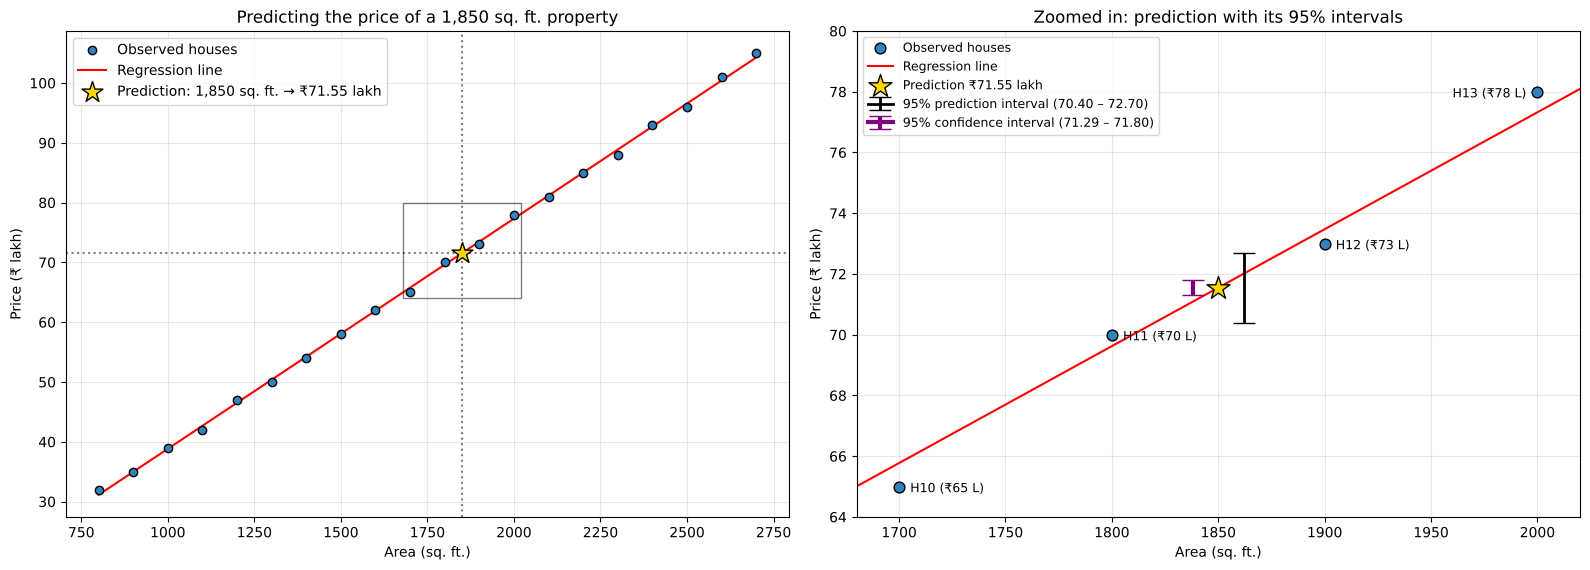

In [16]:
# Left: full data range. Right: zoomed in around 1,850 sq. ft. so the (narrow) intervals are visible.
pi_lo, pi_hi = y_new - t_crit * se_p, y_new + t_crit * se_p
ci_lo, ci_hi = y_new - t_crit * se_m, y_new + t_crit * se_m
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

ax = axes[0]
ax.scatter(x, y, color="#3182bd", edgecolor="black", label="Observed houses", zorder=3)
ax.plot(xs, ys, color="red", label="Regression line")
ax.scatter([x_new], [y_new], color="gold", edgecolor="black", s=250, marker="*", zorder=4,
           label=f"Prediction: 1,850 sq. ft. → ₹{y_new:.2f} lakh")
ax.axvline(x_new, color="grey", ls=":")
ax.axhline(y_new, color="grey", ls=":")
ax.indicate_inset([1680, 64, 340, 16], edgecolor="black")          # box showing the zoomed area
ax.set_xlabel("Area (sq. ft.)")
ax.set_ylabel("Price (₹ lakh)")
ax.set_title("Predicting the price of a 1,850 sq. ft. property")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

ax = axes[1]
ax.scatter(x, y, color="#3182bd", edgecolor="black", s=60, zorder=3, label="Observed houses")
for xi, yi, h in zip(x, y, df["House"]):
    if 1700 <= xi <= 2000:
        right_edge = xi > 1950                     # put the label on the left for the point near the right edge
        ax.annotate(f"{h} (₹{yi:.0f} L)", (xi, yi), xytext=(-8 if right_edge else 8, -4), textcoords="offset points",
                    fontsize=9, ha="right" if right_edge else "left")
ax.plot(xs, ys, color="red", label="Regression line")
ax.errorbar(x_new + 12, y_new, yerr=[[y_new - pi_lo], [pi_hi - y_new]], color="black", capsize=8, lw=2,
            label=f"95% prediction interval ({pi_lo:.2f} – {pi_hi:.2f})")
ax.errorbar(x_new - 12, y_new, yerr=[[y_new - ci_lo], [ci_hi - y_new]], color="purple", capsize=8, lw=3,
            label=f"95% confidence interval ({ci_lo:.2f} – {ci_hi:.2f})")
ax.scatter([x_new], [y_new], color="gold", edgecolor="black", s=300, marker="*", zorder=5,
           label=f"Prediction ₹{y_new:.2f} lakh")
ax.set_xlim(1680, 2020)
ax.set_ylim(64, 80)
ax.set_xlabel("Area (sq. ft.)")
ax.set_ylabel("Price (₹ lakh)")
ax.set_title("Zoomed in: prediction with its 95% intervals")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Explanation:** substituting 1,850 sq. ft. into the equation gives

$$\hat{y} = 0.3316 + 0.038496 \times 1850 = 71.55 \text{ lakh}$$

* This is an **interpolation**: 1,850 sq. ft. lies inside the observed range (800–2,700) and halfway between H11 (1,800 sq. ft., ₹70 lakh) and H12 (1,900 sq. ft., ₹73 lakh). The prediction matches the average of these neighbours (₹71.5 lakh), so it is reliable.
* **95% prediction interval: ₹70.40 to ₹72.70 lakh.** A single 1,850 sq. ft. house would be expected to sell in this range.
* **95% confidence interval: ₹71.29 to ₹71.81 lakh** for the *average* price of all 1,850 sq. ft. houses. It is narrower because it does not include house-to-house variation.
* Caveat: this assumes the new house is similar to the 20 in the sample (same locality and market conditions).

## (h) Limitations and suggested improvements  *(10 marks)*

**Limitations of the model**
1. **Single predictor:** price depends on much more than area: location or locality, age of the building, floor, number of bedrooms and bathrooms, amenities, parking, legal status and market conditions. The near-perfect R² (0.9995) is likely because the sample is small and idealized. Real data will be much noisier.
2. **Small, evenly spaced sample (n = 20):** areas are in exact 100 sq. ft. steps, which looks designed rather than randomly sampled. Results may not generalize.
3. **Extrapolation risk:** the model is valid only for 800–2,700 sq. ft. Predictions for, e.g., a 5,000 sq. ft. villa or a 400 sq. ft. studio are unreliable, and the intercept has no practical meaning.
4. **Linearity assumption:** the residuals hint at a mild (not significant) curvature at the smallest and largest sizes. Over a wider range of sizes the relationship may not stay linear (luxury premiums, diminishing returns).
5. **Time and market effects:** no information on when the houses were sold. Inflation and market cycles change prices over time.
6. **Correlation, not causation:** area is associated with price, but the model does not separate area from what larger houses also tend to have (better locations, more amenities).

**Suggested improvements**
* **Multiple linear regression** with more features (location, age, bedrooms, amenities, floor, distance to city centre or metro), using one-hot encoding for categorical variables such as locality.
* **Collect more data**, randomly sampled across localities and time, and evaluate on a **separate test set** or with **k-fold cross-validation**.
* **Try transformations or non-linear models:** log(price) vs log(area) (an elasticity model), polynomial terms, or tree-based models (Random Forest, Gradient Boosting) when there are many features.
* **Regularization** (Ridge/Lasso) if many correlated features are added, and check **multicollinearity** (VIF).
* **Report prediction intervals**, not just point predictions, so buyers and sellers understand the uncertainty.
* **Regularly re-train** the model with recent sales to capture market changes.